In [ ]:
"""
RAMAS - Automatic Detection of Subjunctive Mood Errors in EFL Learner Spanish
Pipeline: corpus loading → syntactic detection → DSI metrics → decision tree
Corpus: CEDEL2 (English L1 writers), processed with Stanza UD-Spanish
"""

# ════════════════════════════════════════════════════════════════
# DEPENDENCIES
# ════════════════════════════════════════════════════════════════
!pip install stanza pandas scikit-learn matplotlib lxml

import os
import zipfile
import numpy as np
import pandas as pd
import stanza
from collections import deque
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 1.7 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 822.5/822.5 kB 2.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 1.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [stanza]


In [ ]:
# ════════════════════════════════════════════════════════════════
# STANZA PIPELINE — Spanish
# ════════════════════════════════════════════════════════════════
nlp = stanza.Pipeline(
    lang='es',
    processors='tokenize,pos,lemma,depparse',
    use_gpu=False,            # set True if CUDA is available
    tokenize_no_ssplit=False, # allow sentence segmentation
    verbose=False
)

# Quick sanity check
_doc = nlp("El análisis sintáctico con Stanza es eficiente.")
for _sent in _doc.sentences:
  for _w in _sent.words:
    print(f"Word: {_w.text:<12} | Lemma: {_w.lemma:<12} | "
          f"POS: {_w.upos:<6} | Head: {_w.head}")

models/tokenize/combined_nocharlm.pt: reconstructing file:   0%|          |  0.00B /  666kB            

models/tokenize/combined_nocharlm.pt: downloading bytes:           |  0.00B            

models/mwt/combined.pt: reconstructing file:   0%|          |  0.00B /  638kB            

models/mwt/combined.pt: downloading bytes:           |  0.00B            

models/pos/combined_charlm.pt: reconstructing file:   0%|          |  0.00B / 37.9MB            

models/pos/combined_charlm.pt: downloading bytes:           |  0.00B            

... (7 outputs left out)

models/pretrain/conll17.pt: downloading bytes:           |  0.00B            

models/backward_charlm/newswiki.pt: reconstructing file:   0%|          |  0.00B / 20.0MB            

models/backward_charlm/newswiki.pt: downloading bytes:           |  0.00B            

Word: El           | Lemma: el           | POS: DET    | Head: 2
Word: análisis     | Lemma: análisis     | POS: NOUN   | Head: 7
Word: sintáctico   | Lemma: sintáctico   | POS: ADJ    | Head: 2
Word: con          | Lemma: con          | POS: ADP    | Head: 5
Word: Stanza       | Lemma: Stanza       | POS: PROPN  | Head: 2
Word: es           | Lemma: ser          | POS: AUX    | Head: 7
Word: eficiente    | Lemma: eficiente    | POS: ADJ    | Head: 0
Word: .            | Lemma: .            | POS: PUNCT  | Head: 7


In [ ]:
# ════════════════════════════════════════════════════════════════
# CORPUS LOADING — from ZIP file
# ════════════════════════════════════════════════════════════════
from google.colab import files
uploaded     = files.upload()         # select your .zip when the dialog appears
ZIP_FILENAME = list(uploaded.keys())[0]


def score_to_cefr(score):
    """Map CEDEL2 placement test score (0-43) to proficiency band."""
    if score is None:
        return 'UNKNOWN'
    if 0  <= score <= 12: return 'lower_beginner'
    if 13 <= score <= 20: return 'upper_beginner'
    if 21 <= score <= 28: return 'lower_intermediate'
    if 29 <= score <= 35: return 'upper_intermediate'
    if 36 <= score <= 40: return 'lower_advanced'
    if 41 <= score <= 43: return 'upper_advanced'
    return 'UNKNOWN'


def parse_cedel2_txt(filename, content_bytes):
    """
    Parse a CEDEL2 TXT file from its filename and raw bytes.
    Expected filename format: L1_TASKTYPE_SCORE_AGE_YEARS_NTASK_SUBJECTID.txt
    e.g. EN_WR_41_22_7_1_DLM.txt
    """
    stem  = os.path.splitext(os.path.basename(filename))[0]
    parts = stem.split('_')
    text  = content_bytes.decode('utf-8', errors='replace').strip()

    if len(parts) < 7:
        return {
            'subject_id': stem, 'l1': 'UNKNOWN', 'task_type': 'UNKNOWN',
            'score': None, 'CEFR_level': 'UNKNOWN', 'age': None,
            'years_of_study': None, 'task_num': None, 'text': text
        }

    def safe_int(val):
      try:    return int(float(val))
      except: return None


    score = safe_int(parts[2])
    return {
        'subject_id'    : '_'.join(parts[6:]),
        'l1'           : parts[0],
        'task_type'  : parts[1],
        'score'        : score,
        'CEFR_level'   : score_to_cefr(score),
        'age'         : safe_int(parts[3]),
        'years_of_study': safe_int(parts[4]),
        'task_num'    : safe_int(parts[5]),
        'text'        : text
      }


def load_corpus_from_zip(zip_filename):
    """Load all .txt files from a ZIP archive, ignoring macOS metadata."""
    docs = []
    with zipfile.ZipFile(zip_filename, 'r') as zf:
        names = sorted([
            n for n in zf.namelist()
            if n.endswith('.txt') and not n.startswith('__MACOSX')
        ])
        print(f'TXT files found in ZIP: {len(names)}')
        for name in names:
            with zf.open(name) as f:
                docs.append(parse_cedel2_txt(name, f.read()))
    return docs


documents = load_corpus_from_zip(ZIP_FILENAME)
print(f'Documents loaded: {len(documents)}')

df_preview = pd.DataFrame(documents)
print(df_preview[['subject_id', 'CEFR_level', 'score']].to_string())

Saving Corpus_CEDEL2.zip to Corpus_CEDEL2.zip
TXT files found in ZIP: 75
Documents loaded: 75
   subject_id          CEFR_level  score
0         EAC  lower_intermediate     21
1         HIS  lower_intermediate     22
2         LMS  lower_intermediate     23
3         RAC  lower_intermediate     23
4         RRH  lower_intermediate     23
5          EW  lower_intermediate     24
6         SHB  lower_intermediate     24
7         KIF  lower_intermediate     24
8          RD  lower_intermediate     24
9          RK  lower_intermediate     24
10         AB  lower_intermediate     25
11         RK  lower_intermediate     26
12        EGP  lower_intermediate     26
13         JF  lower_intermediate     26
14          C  lower_intermediate     26
15        HNR  lower_intermediate     27
16        BJR  lower_intermediate     27
17        BSJ  lower_intermediate     27
18        KLC  lower_intermediate     28
19         CA  lower_intermediate     28
20         TH  lower_intermediate     28
21  

In [ ]:
# ════════════════════════════════════════════════════════════════
# LINGUISTIC CONTROL LISTS
# ════════════════════════════════════════════════════════════════

# Volitional/emotive verbs: trigger obligatory subjunctive with subject change
VOLITIONAL_VERBS = {
    'querer','desear','esperar','pedir', 'rogar', 'necesitar',
    'insistir','exigir','recomendar','sugerir','ordenar',
    'proponer','preferir','permitir','prohibir','impedir',
    'dudar','negar','temer','lamentar','alegrarse',
    'sorprender','extrañar','parecer','suponer', 'apetecer',
    'suplicar', 'aconsejar', 'demandar', 'mandar', 'consentir',
    'autorizar', 'dejar', 'tolerar', 'convencer', 'persuadir'
}

# Final/purpose conjunctions: obligatorily followed by subjunctive
FINAL_CONNECTORS = {
    ('para', 'que'), ('antes', 'de', 'que'),
    ('sin', 'que'), ('a', 'menos', 'que'), ('a', 'menos', 'de', 'que'),
    ('con', 'tal', 'de', 'que'), ('con', 'tal', 'que'),
    ('a', 'fin', 'de', 'que'),
    ('de', 'modo', 'que'), ('de', 'manera', 'que'), ('de', 'forma', 'que'),
    ('una', 'vez', 'que'),
}

# Epistemic/reportative verbs: standard norm requires indicative;
# subjunctive after these = hypercorrection
INDICATIVE_TRIGGER_VERBS = {
    'creer','pensar','considerar','opinar','decir',
    'afirmar','saber','ver','notar','imaginar',
    'entender', 'comprender', 'suponer', 'asumir',
    'deducir', 'concluir', 'sospechar', 'juzgar',
    'observar', 'percibir',
    'oir', 'escuchar', 'comprobar', 'constatar',
    'asegurar', 'sostener', 'declarar', 'manifestar',
    'comunicar', 'informar', 'notificar', 'explicar',
    'exponer', 'señalar', 'apuntar', 'demostrar',
    'probar', 'recordar', 'olvidar'
}

# Evaluative predicates: trigger subjunctive as clausal subject/complement
EVALUATIVE_PREDICATES = {
    'importante', 'necesario', 'bueno', 'malo', 'mejor', 'peor',
    'esencial', 'fundamental', 'preferible', 'posible', 'imposible',
    'partidario', 'partidaria',
}

# Indefinite pronouns that can head a relative clause requiring subjunctive
INDEFINITE_PRONOUNS = {'alguien', 'nadie', 'algo', 'nada', 'quien', 'quienes'}

In [ ]:
# ════════════════════════════════════════════════════════════════
# HELPER FUNCTIONS
# ════════════════════════════════════════════════════════════════

def get_feat(feats_str, feature_name):
  """
  Extract the value of a UD morphological feature from a Stanza feats string.
  e.g. get_feat('Mood=Sub|Number=Sing', 'Mood') -> 'Sub'
  """
  if not feats_str:
    return ''
  for feat in feats_str.split('|'):
      if feat.startswith(feature_name + '='):
        return feat.split('=')[1]
  return ''

def has_explicit_subject(v_sub, sentence):
    """
    Return True if the subordinate verb has its own explicit subject (nsubj),
    indicating a subject change relative to the matrix verb.
    Return False if the subject is likely coreferential (implicit, same subject).
    Coreferential infinitives are grammatically correct and should not be
    counted as elision errors.
    """
    return any(
        cand.head == v_sub.id and cand.deprel in ('nsubj', 'nsubj:pass')
        for cand in sentence.words
    )

In [ ]:
import pandas as pd
import stanza
from collections import deque

# ════════════════════════════════════════════════════════════════
# SCENARIO DETECTORS
# ════════════════════════════════════════════════════════════════

def detect_scenario_A(sentence):
    """
    Scenario A — Volitional/epistemic matrix verb + subordinate clause.

    Correctly handles modal chains (e.g. 'espero que pueda viajar'):
    if the direct dependent is an infinitive, checks for a modal auxiliary
    bearing the Mood feature.

    Coreferential infinitives (same subject) are discarded, not counted as Elision.
    Indicative after INDICATIVE_TRIGGER_VERBS is discarded (not a subjunctive context).
    Subjunctive after INDICATIVE_TRIGGER_VERBS = Hypercorrection.
    """
    cases = []
    for w in sentence.words:
        if w.upos not in ('VERB', 'AUX'):
            continue
        lemma = w.lemma.lower()
        is_volitional  = lemma in VOLITIONAL_VERBS
        is_ind_trigger = lemma in INDICATIVE_TRIGGER_VERBS
        if not (is_volitional or is_ind_trigger):
            continue

        # Collect all direct ccomp/xcomp dependents
        candidates = [
            c for c in sentence.words
            if c.head == w.id and c.upos in ('VERB', 'AUX')
            and c.deprel in ('ccomp', 'xcomp')
        ]
        if not candidates:
            continue

        v_sub     = candidates[0]
        verb_form = get_feat(v_sub.feats, 'VerbForm')
        mood      = get_feat(v_sub.feats, 'Mood')

        # Handle modal chains: if v_sub is bare infinitive, check for
        # an auxiliary (e.g. 'pueda') that carries the actual Mood
        if verb_form == 'Inf' and not mood:
            for aux in sentence.words:
                if aux.head == v_sub.id and aux.deprel == 'aux' and aux.upos == 'AUX':
                    mood_aux = get_feat(aux.feats, 'Mood')
                    if mood_aux in ('Sub', 'Ind'):
                        v_sub     = aux
                        verb_form = get_feat(aux.feats, 'VerbForm')
                        mood      = mood_aux
                        break

        target = None
        if is_volitional and verb_form == 'Inf':
            # Coreferential infinitive = grammatical, not an error
            target = 'Elision_Infinitive' if has_explicit_subject(v_sub, sentence) else None
        elif is_volitional and mood == 'Sub':
            target = 'Correct'
        elif is_volitional and mood == 'Ind':
            target = 'Elision_Indicative'
        elif is_ind_trigger and mood == 'Sub':
            target = 'Hypercorrection'
        elif is_ind_trigger and mood == 'Ind':
            target = None   # indicative is the only correct option here

        if target:
            cases.append({
                'id_matrix_verb': w.id,
                'matrix_lemma'    : lemma,
                'matrix_type'    : 'Volition' if is_volitional else 'Indicative_Trigger',
                'id_sub_verb'   : v_sub.id,
                'sub_form'      : v_sub.text,
                'verb_form'      : verb_form,
                'mood'           : mood,
                'target_class'   : target
            })
    return cases


def detect_scenario_B(sentence):
    """
    Scenario B — Indefinite noun phrase or indefinite pronoun + relative clause.

    The relative clause verb should be in subjunctive (inespecific/hypothetical
    referent). Indicative in this context = Elision.

    Past-tense indicative relatives are excluded: if the event already occurred,
    the referent is specific and indicative is correct.
    """
    cases = []
    INDEFINITE_DETERMINERS = {
        'un', 'uno', 'una',
        'todo', 'toda', 'todos', 'todas',
        'cualquier', 'cualquiera',
        'algún', 'alguno', 'alguna', 'algunos', 'algunas',
        'ningún', 'ninguno', 'ninguna',
    }

    nucleus_candidates = []
    for w in sentence.words:
        if w.upos == 'NOUN':
            has_indef = any(
                d.head == w.id and d.deprel == 'det'
                and d.lemma.lower() in INDEFINITE_DETERMINERS
                for d in sentence.words
            )
            if has_indef:
                nucleus_candidates.append(w)
        elif w.upos == 'PRON' and w.lemma.lower() in INDEFINITE_PRONOUNS:
            nucleus_candidates.append(w)

    for nucleus in nucleus_candidates:
        for v_rel in sentence.words:
            if v_rel.head != nucleus.id or v_rel.deprel not in ('acl:relcl', 'acl'):
                continue
            if v_rel.upos not in ('VERB', 'AUX'):
                continue

            verb_form = get_feat(v_rel.feats, 'VerbForm')
            mood      = get_feat(v_rel.feats, 'Mood')
            tense     = get_feat(v_rel.feats, 'Tense')

            # Exclude past indicative: specific referent, indicative is correct
            if tense in ('Past', 'Imp') and mood == 'Ind':
                continue

            if verb_form == 'Inf':
                target = 'Elision_Infinitive'
            elif mood == 'Sub':
                target = 'Correct'
            elif mood == 'Ind':
                target = 'Elision_Indicative'
            else:
                continue

            cases.append({
                'id_matrix_verb': nucleus.id,
                'matrix_lemma'    : nucleus.lemma,
                'matrix_type'    : 'Indefinite_Relative',
                'id_sub_verb'   : v_rel.id,
                'sub_form'      : v_rel.text,
                'verb_form'      : verb_form,
                'mood'           : mood,
                'target_class'   : target
            })
    return cases

def detect_scenario_C(sentence):
    """
    Scenario C — Final/purpose conjunctions followed by verb.
    Subjunctive obligatory after all connectors in FINAL_CONNECTORS.
    Infinitive or indicative after them = Elision.
    """
    cases        = []
    words        = sentence.words
    tokens_lower = [w.text.lower() for w in words]

    for i, w in enumerate(words):
        connector_found = None
        connector_len   = 0
        for conn in FINAL_CONNECTORS:
            n = len(conn)
            if tokens_lower[i:i + n] == list(conn):
                connector_found = conn
                connector_len = n
                break

        if connector_found is None:
            continue

        next_idx = i + connector_len
        if next_idx >= len(words):
            continue

        v_sub = words[next_idx]
        if v_sub.upos not in ('VERB', 'AUX'):
            found = False
            for j in range(next_idx, min(next_idx + 3, len(words))):
                if words[j].upos in ('VERB', 'AUX'):
                    v_sub = words[j]
                    found = True
                    break
            if not found:
                continue

        verb_form = get_feat(v_sub.feats, 'VerbForm')
        mood      = get_feat(v_sub.feats, 'Mood')

        if verb_form == 'Inf':
            target = 'Elision_Infinitive'
        elif mood == 'Sub':
            target = 'Correct'
        elif mood == 'Ind':
            target = 'Elision_Indicative'
        else:
            continue


        cases.append({
            'id_matrix_verb': w.head,
            'matrix_lemma'    : ' '.join(connector_found),
            'matrix_type'    : 'Final_Connector',
            'id_sub_verb'    : v_sub.id,
            'sub_form'      : v_sub.text,
            'verb_form'      : verb_form,
            'mood'           : mood,
            'target_class'   : target
        })
    return cases

def detect_scenario_D(sentence):
    """
    Scenario D — Evaluative predicate (adjective/noun) + subordinate clause.
    e.g. 'es importante que', 'no soy partidaria de que'.

    Handles nested copular structures: if the direct dependent is a predicative
    adjective with its own copula, the copula carries the actual Mood.

    Coreferential infinitives (generic impersonal constructions such as
    'es fundamental cambiar') are excluded, not counted as Elision.
    """
    cases = []
    for w in sentence.words:
        if w.upos not in ('ADJ', 'NOUN'):
            continue
        if w.lemma.lower() not in EVALUATIVE_PREDICATES:
            continue

        v_sub = None
        for cand in sentence.words:
            if cand.head != w.id:
                continue
            if cand.upos in ('VERB', 'AUX') and cand.deprel in ('ccomp', 'csubj', 'advcl'):
                v_sub = cand
                break
            # Nested copular predicate: 'no soy partidaria de que esté casada'
            if cand.upos == 'ADJ' and cand.deprel == 'acl':
                for cop in sentence.words:
                    if cop.head == cand.id and cop.deprel == 'cop' and cop.upos == 'AUX':
                        v_sub = cop
                        break
                if v_sub:
                    break

        if v_sub is None:
            continue

        verb_form = get_feat(v_sub.feats, 'VerbForm')
        mood      = get_feat(v_sub.feats, 'Mood')

        target = None
        if verb_form == 'Inf':
          # Generic impersonal infinitive = grammatical, not an error
           target = 'Elision_Infinitive' if has_explicit_subject(v_sub, sentence) else None
        elif mood == 'Sub':
            target = 'Correct'
        elif mood == 'Ind':
            target = 'Elision_Indicative'

        if target:
            cases.append({
                'id_matrix_verb': w.id,
                'matrix_lemma'    : w.lemma,
                'matrix_type'    : 'Evaluative_Predicate',
                'id_sub_verb'   : v_sub.id,
                'sub_form'      : v_sub.text,
                'verb_form'      : verb_form,
                'mood'           : mood,
                'target_class'   : target
            })
    return cases


In [ ]:
# ════════════════════════════════════════════════════════════════
# SYNTACTIC METRICS
# ════════════════════════════════════════════════════════════════

def calculate_dsi(sentence, id_matrix_verb, id_sub_verb):
    """
    Interverbal Syntactic Distance (DSI) between two verbs.

    Returns:
        linear_distance      (DL): linear token distance between the two verbs
        syntactic_depth (PS): graph distance in the dependency tree (BFS)

    Based on Liu (2008) — Mean Dependency Distance as a measure of
    syntactic processing complexity.
    """
    DL = max(0, abs(id_sub_verb - id_matrix_verb) - 1)

    graph = {w.id: [] for w in sentence.words}
    graph[0] = []
    for w in sentence.words:
        graph[w.id].append(w.head)
        graph.setdefault(w.head, []).append(w.id)

    visited = {id_matrix_verb}
    queue   = deque([(id_matrix_verb, 0)])
    PS      = -1
    while queue:
        node, dist = queue.popleft()
        if node == id_sub_verb:
            PS = dist
            break
        for neighbour in graph.get(node, []):
            if neighbour not in visited:
                visited.add(neighbour)
                queue.append((neighbour, dist + 1))

    return {'linear_distance': DL, 'syntactic_depth': PS}


def calculate_mdd(sentence):
    """Mean Dependency Distance (MDD for the ful sentence (Liu, 2008)."""
    distances = [abs(w.id - w.head) for w in sentence.words if w.head != 0]
    return sum(distances) / len(distances) if distances else 0.0

In [ ]:
# ════════════════════════════════════════════════════════════════
# STEP A — Detector verification on control sentences
# ════════════════════════════════════════════════════════════════

CONTROL_SENTENCES = [
    ("Quisiera obtener un trabajo.",           "[] - coreferential infinitive, no case"),
    ("Pienso que tienes razón.",               "[] - indicative trigger + Ind, no case"),
    ("Espero que pueda viajar mañana.",        "Scenario A: Correct (modal chain)"),
    ("Es importante que vengas temprano.",     "Scenario D: Correct (evaluative predicative)"),
    ("Necesito a alguien que me ayude.",       "Scenario B: Correct (indefinite pronoun)"),
    ("Lo haré de modo que todos entiendan.",   "Scenario C: Correct (extended connector)"),
]

print("=" * 70)
print("STEP A - CONTROL SENTENCE VERIFICATION")
print("=" * 70)
for sentence_text, expected in CONTROL_SENTENCES:
    doc = nlp(sentence_text)
    for sent in doc.sentences:
        a = detect_scenario_A(sent)
        b = detect_scenario_B(sent)
        c = detect_scenario_C(sent)
        d = detect_scenario_D(sent)
        print(f"\nSentence : {sentence_text}")
        print(f"Expected : {expected}")
        print(f"  A: {a}")
        print(f"  B: {b}")
        print(f"  C: {c}")
        print(f"  D: {d}")

STEP A - CONTROL SENTENCE VERIFICATION

Sentence : Quisiera obtener un trabajo.
Expected : [] - coreferential infinitive, no case
  A: []
  B: []
  C: []
  D: []

Sentence : Pienso que tienes razón.
Expected : [] - indicative trigger + Ind, no case
  A: []
  B: []
  C: []
  D: []

Sentence : Espero que pueda viajar mañana.
Expected : Scenario A: Correct (modal chain)
  A: [{'id_matrix_verb': 1, 'matrix_lemma': 'esperar', 'matrix_type': 'Volition', 'id_sub_verb': 3, 'sub_form': 'pueda', 'verb_form': 'Fin', 'mood': 'Sub', 'target_class': 'Correct'}]
  B: []
  C: []
  D: []

Sentence : Es importante que vengas temprano.
Expected : Scenario D: Correct (evaluative predicative)
  A: []
  B: []
  C: []
  D: [{'id_matrix_verb': 2, 'matrix_lemma': 'importante', 'matrix_type': 'Evaluative_Predicate', 'id_sub_verb': 4, 'sub_form': 'vengas', 'verb_form': 'Fin', 'mood': 'Sub', 'target_class': 'Correct'}]

Sentence : Necesito a alguien que me ayude.
Expected : Scenario B: Correct (indefinite pronoun

In [ ]:
# ════════════════════════════════════════════════════════════════
# STEP B — Process each document in the corpus
# ════════════════════════════════════════════════════════════════

def process_document(doc_dict, nlp_pipeline):
    """
    Run all four scenario detectors over a single corpus document.
    Returns a list of case dictionaries with DSI and MDD metrics.
    """
    subject_id = doc_dict['subject_id']
    cefr_level = doc_dict['CEFR_level']
    text       = doc_dict['text']

    if not text or not text.strip():
        return []

    try:
        doc = nlp_pipeline(text)
    except Exception as exc:
        print(f'\n⚠️  Error processing {subject_id}: {exc}')
        return []

    rows = []
    for sentence in doc.sentences:
        detectors = [
            detect_scenario_A(sentence),
            detect_scenario_B(sentence),
            detect_scenario_C(sentence),
            detect_scenario_D(sentence),
        ]
        for cases in detectors:
            for case in cases:
              dsi = calculate_dsi(
                  sentence,
                  case['id_matrix_verb'],
                  case['id_sub_verb']
              )
              mdd = calculate_mdd(sentence)

              matrix_type = case['matrix_type']
              if matrix_type in ('Volition', 'Final_Connector',
                                 'Indefinite_Relative', 'Evaluative_Predicate'):
                model = 'M1_elision'
              elif matrix_type == 'Indicative_Trigger':
                model = 'M2_hypercorrection'
              else:
                model = 'UNKNOWN'

              rows.append({
                    'ID_Subject'          : subject_id,
                    'Model'               : model,
                    'CEFR_Level'          : cefr_level,
                    'Matrix_Type'         : case['matrix_type'],
                    'Trigger_Lemma'       : case['matrix_lemma'],
                    'SubVerb_Form'        : case['sub_form'],
                    'Linear_Distance'     : dsi['linear_distance'],
                    'Syntactic_Depth'     : dsi['syntactic_depth'],
                    'MDD_Sentence'        : round(mdd, 3),
                    'Target_Class'        : case['target_class'],
                })
    return rows

# Run over the full corpus
results = []
for i, doc_dict in enumerate(documents, 1):
    print(f'Processing {i}/{len(documents)}: {doc_dict["subject_id"]}')
    results.extend(process_document(doc_dict, nlp))

df = pd.DataFrame(results)
print(f'\nTotal cases detected: {len(df)}')

if len(df) > 0:
    print(df['Target_Class'].value_counts())
else:
    print('No cases detected. Check that the texts contain the expected patterns.')


Processing 1/75: EAC
Processing 2/75: HIS
Processing 3/75: LMS
Processing 4/75: RAC
Processing 5/75: RRH
Processing 6/75: EW
Processing 7/75: SHB
Processing 8/75: KIF
Processing 9/75: RD
Processing 10/75: RK
Processing 11/75: AB
Processing 12/75: RK
Processing 13/75: EGP
Processing 14/75: JF
Processing 15/75: C
Processing 16/75: HNR
Processing 17/75: BJR
Processing 18/75: BSJ
Processing 19/75: KLC
Processing 20/75: CA
Processing 21/75: TH
Processing 22/75: THM
Processing 23/75: AM
Processing 24/75: KW
Processing 25/75: CMF
Processing 26/75: AJJ
Processing 27/75: RCR
Processing 28/75: MK
Processing 29/75: RCF
Processing 30/75: MAH
Processing 31/75: SP
Processing 32/75: CALS
Processing 33/75: JJNE
Processing 34/75: AA
Processing 35/75: AJ
Processing 36/75: JMG
Processing 37/75: KS
Processing 38/75: ASA
Processing 39/75: HES
Processing 40/75: CAL
Processing 41/75: KB
Processing 42/75: REB
Processing 43/75: LS
Processing 44/75: SCR
Processing 45/75: JAS
Processing 46/75: LJ
Processing 47/7

In [ ]:
# ════════════════════════════════════════════════════════════════
# STEP C — Dataset cleaning and CEFR level mapping
# ════════════════════════════════════════════════════════════════

df = pd.DataFrame(results)

df = pd.DataFrame(results)
df['Target_Class'] = df['Target_Class'].replace({'Elision_Inficative': 'Elision_Indicative'})
assert 'Elision_Inficative' not in set(df['Target_Class']), "Quedan etiquetas con la errata"

if len(df) == 0:
    raise ValueError("Empty DataFrame — check Step B before continuing.")

# Remove cases where the dependency path was not found (PS == -1)
before = len(df)
df = df[df['Syntactic_Depth'] != -1].copy()
print(f"Rows removed (Syntactic_Depth == -1): {before - len(df)}")

# Map CEDEL2 internal bands to three CEFR levels used in the study.
# lower_beginner excluded (too few subjunctive contexts at that level).
# Mapping rationale (Gudmestad 2006; CEDEL2 documentation):
#   upper_beginner + lower_intermediate → B1
#   upper_intermediate                  → B2
#   lower_advanced + upper_advanced     → C1
cefr_mapping = {
    'lower_beginner'    : 'A1',
    'upper_beginner'    : 'A2',
    'lower_intermediate': 'B1',
    'upper_intermediate': 'B2',
    'lower_advanced'    : 'C1',
    'upper_advanced'    : 'C2',
}

df['CEFR_Level'] = df['CEFR_Level'].map(cefr_mapping)
before = len(df)
df = df[df['CEFR_Level'].isin(['B1', 'B2', 'C1'])].copy()
print(f"Rows removed (level outside B1-C1): {before - len(df)}")

df['Linear_Distance'] = df['Linear_Distance'].astype(int)
df['CEFR_Level'] = pd.Categorical(
    df['CEFR_Level'], categories=['B1', 'B2', 'C1'], ordered=True
)

print("\nCases by level and class:")
print(df.groupby(['CEFR_Level', 'Target_Class'], observed=True).size().unstack(fill_value=0))
print(f"\nTotal cases after cleaning: {len(df)}")
print(df['Target_Class'].value_counts())

df.to_csv('dataset_subjunctive.csv', index=False, encoding='utf-8-sig')
print("\nDataset exported → dataset_subjunctive.csv")

# ── M1: Correct vs Elision_Indicative vs Elision_Infinitive (3 clases) ──
M1_CLASSES = ['Correct', 'Elision_Indicative', 'Elision_Infinitive']
df_m1 = df[(df['Model'] == 'M1_elision') & df['Target_Class'].isin(M1_CLASSES)].copy()
# Standardize binary target for tree logic mapping 'Correct' as 1, others as 0
df_m1['Binary_Target'] = (df_m1['Target_Class'] == 'Correct').astype(int)

# ── M2: indicative-trigger contexts (descriptivo si solo hay Hypercorrection) ──
df_m2 = df[df['Model'] == 'M2_hypercorrection'].copy()
df_m2 = df_m2[df_m2['Target_Class'].isin(['Correct', 'Hypercorrection'])]
df_m2['Binary_Target'] = (df_m2['Target_Class'] == 'Correct').astype(int)

print(f"\nM1: {len(df_m1)} cases")
print(df_m1['Target_Class'].value_counts().to_string())
print(f"\nM2: {len(df_m2)} cases — Hypercorrection: "
      f"{(df_m2['Target_Class'] == 'Hypercorrection').sum()}")

Rows removed (Syntactic_Depth == -1): 0
Rows removed (level outside B1-C1): 0

Cases by level and class:
Target_Class  Correct  Elision_Indicative  Elision_Infinitive  Hypercorrection
CEFR_Level                                                                    
B1                  6                  25                   6                2
B2                 11                  48                   7                4
C1                 21                  36                  12                9

Total cases after cleaning: 187
Target_Class
Elision_Indicative    109
Correct                38
Elision_Infinitive     25
Hypercorrection        15
Name: count, dtype: int64

Dataset exported → dataset_subjunctive.csv

M1: 172 cases
Target_Class
Elision_Indicative    109
Correct                38
Elision_Infinitive     25

M2: 15 cases — Hypercorrection: 15


In [ ]:
# ════════════════════════════════════════════════════════════════
# STEP D — Feature encoding and decision tree training
# ════════════════════════════════════════════════════════════════
CEFR_ORDER = ['B1', 'B2', 'C1']
le_cefr = LabelEncoder()
le_cefr.fit(CEFR_ORDER)

df_m1 = df_m1.copy()
df_m2 = df_m2.copy()

# Create Target_enc explicitly mapping M1_CLASSES to integer labels [0, 1, 2]
M1_CLASSES = ['Correct', 'Elision_Indicative', 'Elision_Infinitive']
class_mapping = {label: idx for idx, label in enumerate(M1_CLASSES)}
df_m1['Target_enc'] = df_m1['Target_Class'].map(class_mapping)

df_m1['CEFR_encoded'] = le_cefr.transform(df_m1['CEFR_Level'].astype(str))
df_m2['CEFR_encoded'] = le_cefr.transform(df_m2['CEFR_Level'].astype(str))

FEATURES = ['Linear_Distance', 'Syntactic_Depth', 'MDD_Sentence', 'CEFR_encoded']

# ── M1: Correct vs Elision_Indicative vs Elision_Infinitive ──
print("\n" + "═" * 70)
print("TREE M1 — Obligatory subjunctive (Correct / Elision_Indicative / Elision_Infinitive)")
print("═" * 70)

if len(df_m1) < 10:
    print(f"⚠ Only {len(df_m1)} cases in M1. Expand the corpus before interpreting results.")
else:
    X1 = df_m1[FEATURES].values
    y1 = df_m1['Target_enc'].values
    min_class_m1 = pd.Series(y1).value_counts().min()

    try:
        X1_train, X1_test, y1_train, y1_test = train_test_split(
            X1, y1, test_size=0.25, random_state=42, stratify=y1
        )
    except ValueError as e:
        print(f"⚠ Stratified split failed ({e}). Using simple split.")
        X1_train, X1_test, y1_train, y1_test = train_test_split(
            X1, y1, test_size=0.25, random_state=42
        )

    tree_m1 = DecisionTreeClassifier(
        criterion='gini', max_depth=3, min_samples_leaf=3,
        class_weight='balanced', random_state=42
    )
    tree_m1.fit(X1_train, y1_train)
    y1_pred = tree_m1.predict(X1_test)

    print("\n--- Classification Report M1 ---")
    print(classification_report(
        y1_test, y1_pred, labels=[0, 1, 2],
        target_names=M1_CLASSES, zero_division=0
    ))

    cv_folds_m1 = min(5, min_class_m1) if min_class_m1 >= 2 else None
    if cv_folds_m1:
        scores_m1 = cross_val_score(tree_m1, X1, y1, cv=cv_folds_m1, scoring='f1_macro')
        print(f'F1-macro CV M1 ({cv_folds_m1}-fold): '
              f'{scores_m1.mean():.3f} ± {scores_m1.std():.3f}')
    else:
        print("⚠ Insufficient examples per class for cross-validation in M1.")

    print("\n── Decision Rules M1 ──")
    print(export_text(tree_m1, feature_names=FEATURES))

    importances_m1 = pd.Series(
        tree_m1.feature_importances_, index=FEATURES
    ).sort_values(ascending=False)
    print('\nFeature Importance M1 (Gini):')
    print(importances_m1.to_string())

# ── M2: Indicative-trigger contexts (Correct vs Hypercorrection) ──
print("\n" + "═" * 70)
print("TREE M2 — Indicative-trigger contexts (Correct vs Hypercorrection)")
print("═" * 70)

n_classes_m2 = df_m2['Target_Class'].nunique() if len(df_m2) > 0 else 0

if len(df_m2) < 10 or n_classes_m2 < 2:
    print(f"⚠ M2: {len(df_m2)} cases, {n_classes_m2} class(es). Descriptive analysis only.")
    if len(df_m2) > 0:
        print(df_m2[['CEFR_Level', 'Target_Class', 'Linear_Distance']].to_string())
        print("\nLinear_Distance by CEFR level (M2):")
        print(df_m2.groupby('CEFR_Level', observed=True)['Linear_Distance']
              .agg(['count', 'mean', 'std']).round(2))
        print("\nLinear_Distance overall (M2):")
        print(df_m2['Linear_Distance'].agg(['count', 'mean', 'std']).round(2))
else:
    X2 = df_m2[FEATURES].values
    y2 = df_m2['Binary_Target'].values
    min_class_m2 = pd.Series(y2).value_counts().min()
    try:
        X2_train, X2_test, y2_train, y2_test = train_test_split(
            X2, y2, test_size=0.25, random_state=42, stratify=y2
        )
    except ValueError as e:
        print(f"⚠ Stratified split failed ({e}). Using simple split.")
        X2_train, X2_test, y2_train, y2_test = train_test_split(
            X2, y2, test_size=0.25, random_state=42
        )
    tree_m2 = DecisionTreeClassifier(
        criterion='gini', max_depth=3, min_samples_leaf=3,
        class_weight='balanced', random_state=42
    )
    tree_m2.fit(X2_train, y2_train)
    y2_pred = tree_m2.predict(X2_test)
    print(classification_report(
        y2_test, y2_pred, target_names=['Hypercorrection', 'Correct'], zero_division=0
    ))
    print(export_text(tree_m2, feature_names=FEATURES))


══════════════════════════════════════════════════════════════════════
TREE M1 — Obligatory subjunctive (Correct / Elision_Indicative / Elision_Infinitive)
══════════════════════════════════════════════════════════════════════

--- Classification Report M1 ---
                    precision    recall  f1-score   support

           Correct       0.57      0.40      0.47        10
Elision_Indicative       0.69      0.81      0.75        27
Elision_Infinitive       0.00      0.00      0.00         6

          accuracy                           0.60        43
         macro avg       0.42      0.40      0.41        43
      weighted avg       0.56      0.60      0.58        43

F1-macro CV M1 (5-fold): 0.269 ± 0.051

── Decision Rules M1 ──
|--- Linear_Distance <= 0.50
|   |--- MDD_Sentence <= 3.37
|   |   |--- CEFR_encoded <= 0.50
|   |   |   |--- class: 2
|   |   |--- CEFR_encoded >  0.50
|   |   |   |--- class: 0
|   |--- MDD_Sentence >  3.37
|   |   |--- class: 1
|--- Linear_Distance

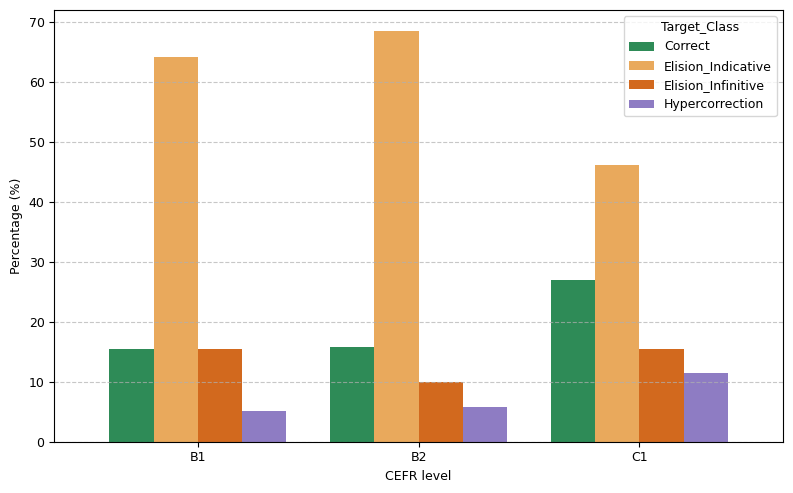

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
                     'xtick.labelsize': 9, 'ytick.labelsize': 9})
LEVELS  = ['B1', 'B2', 'C1']
CLASSES = ['Correct', 'Elision_Indicative', 'Elision_Infinitive', 'Hypercorrection']
COLORS  = {'Correct': '#2E8B57', 'Elision_Indicative': '#E9A95C',
           'Elision_Infinitive': '#D2691E', 'Hypercorrection': '#8E7CC3',
           'Elision': '#D2691E'}
MERGE_ELISION = False

df['CEFR_Level'] = pd.Categorical(df['CEFR_Level'].astype(str), categories=LEVELS, ordered=True)

def save(fig, name):
    fig.savefig(f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(f'{name}.svg', bbox_inches='tight')
    plt.show()
    try:
        from google.colab import files
        files.download(f'{name}.png')
    except Exception:
        pass

plot_df = df.copy()
if MERGE_ELISION:
    plot_df['Target_Class'] = plot_df['Target_Class'].replace(
        {'Elision_Indicative': 'Elision', 'Elision_Infinitive': 'Elision'})
    CL1 = ['Correct', 'Elision', 'Hypercorrection']
else:
    CL1 = CLASSES

cross_tab = pd.crosstab(plot_df['CEFR_Level'], plot_df['Target_Class'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(8, 5))
cross_tab[CL1].plot(kind='bar', color=[COLORS[c] for c in CL1], width=0.8, ax=ax)
ax.set_ylabel('Percentage (%)')
ax.set_xlabel('CEFR level')
ax.set_xticklabels(LEVELS, rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

save(fig, 'figura_1_distribucion_errores')

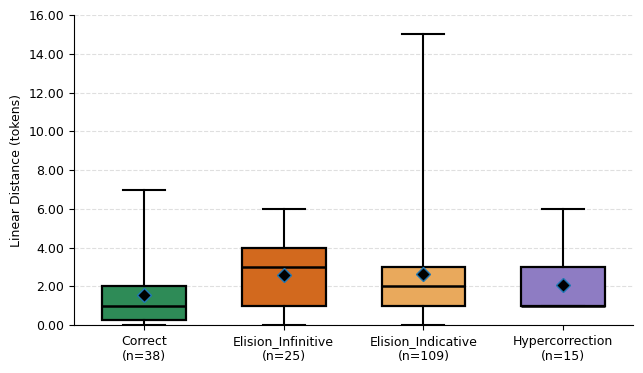

                    count  mean   std  min   25%  50%  75%   max
Target_Class                                                    
Correct              38.0  1.55  1.54  0.0  0.25  1.0  2.0   7.0
Elision_Infinitive   25.0  2.60  1.78  0.0  1.00  3.0  4.0   6.0
Elision_Indicative  109.0  2.64  2.33  0.0  1.00  2.0  3.0  15.0
Hypercorrection      15.0  2.07  1.49  1.0  1.00  1.0  3.0   6.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

CLASSES = ['Correct', 'Elision_Infinitive', 'Elision_Indicative', 'Hypercorrection']
COLORS  = ['#2E8B57', '#D2691E', '#E9A95C', '#8E7CC3']

data = [df.loc[df['Target_Class'] == c, 'Linear_Distance'].astype(float) for c in CLASSES]
labels = [f'{c}\n(n={len(d)})' for c, d in zip(CLASSES, data)]

plt.rcParams.update({'font.size': 9})
fig, ax = plt.subplots(figsize=(6.5, 3.8))

bp = ax.boxplot(
    data, patch_artist=True, widths=0.6,
    whis=(0, 100),
    showmeans=True,
    boxprops=dict(edgecolor='black', linewidth=1.6),
    medianprops=dict(color='black', linewidth=1.8),
    whiskerprops=dict(color='black', linewidth=1.5),
    capprops=dict(color='black', linewidth=1.5),
    meanprops=dict(marker='D', markerfacecolor='black',
                   markeredgecolor='#1F77B4', markersize=7),
    flierprops=dict(marker='')
)
for patch, col in zip(bp['boxes'], COLORS):
    patch.set_facecolor(col)

ax.set_xticklabels(labels)
ax.set_ylabel('Linear Distance (tokens)')
ax.set_ylim(0, max(d.max() for d in data) + 1)
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax.grid(axis='y', linestyle='--', alpha=0.4); ax.set_axisbelow(True)
for s in ('top', 'right'): ax.spines[s].set_visible(False)

plt.tight_layout()
fig.savefig('fig2_isd_by_class.png', dpi=300, bbox_inches='tight')
fig.savefig('fig2_isd_by_class.svg', bbox_inches='tight')
plt.show()

print(df.groupby('Target_Class')['Linear_Distance']
        .describe(percentiles=[.25, .5, .75]).round(2).loc[CLASSES])

save(fig, 'figure2')

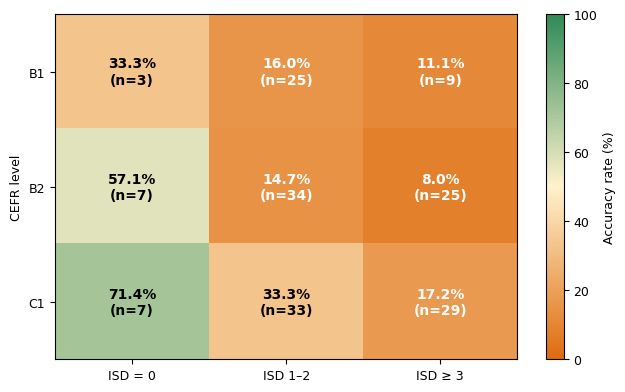

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

LEVELS = ['B1', 'B2', 'C1']
BANDS  = ['ISD = 0', 'ISD 1–2', 'ISD ≥ 3']

m1 = df[df['Model'] == 'M1_elision'].copy()
m1['CEFR_Level'] = pd.Categorical(m1['CEFR_Level'].astype(str), categories=LEVELS, ordered=True)
m1['Correct'] = (m1['Target_Class'] == 'Correct').astype(int)
m1['ISD_band'] = pd.cut(m1['Linear_Distance'], bins=[-1, 0, 2, np.inf], labels=BANDS)

g   = m1.groupby(['CEFR_Level', 'ISD_band'], observed=False)['Correct'].agg(['mean', 'count'])
acc = (g['mean'].unstack().reindex(index=LEVELS, columns=BANDS) * 100)
n   = g['count'].unstack().reindex(index=LEVELS, columns=BANDS)

cmap = LinearSegmentedColormap.from_list('or_yl_gr', ['#DE6B0F', '#FFF2CC', '#2E8B57'])

fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(acc.values, cmap=cmap, vmin=0, vmax=100, aspect='auto')

for r in range(len(LEVELS)):
    for c in range(len(BANDS)):
        val = acc.values[r, c]
        count = n.values[r, c]
        text_color = 'white' if val < 25 or val > 75 else 'black'
        ax.text(c, r, f'{val:.1f}%\n(n={count})', ha='center', va='center',
                color=text_color, fontweight='bold', fontsize=10)

ax.set_xticks(np.arange(len(BANDS)))
ax.set_yticks(np.arange(len(LEVELS)))
ax.set_ylabel('CEFR level')
ax.set_xticklabels(BANDS)
ax.set_yticklabels(LEVELS)

cbar = fig.colorbar(im, ax=ax, label='Accuracy rate (%)')
plt.tight_layout()

fig.savefig('fig3_heatmap_isd.png', dpi=300, bbox_inches='tight')
fig.savefig('fig3_heatmap_isd.svg', bbox_inches='tight')
plt.show()

try:
    from google.colab import files as colab_files
    colab_files.download('fig3_heatmap_isd.png')
    colab_files.download('fig3_heatmap_isd.svg')
except Exception:
    pass


save(fig, 'figure3')

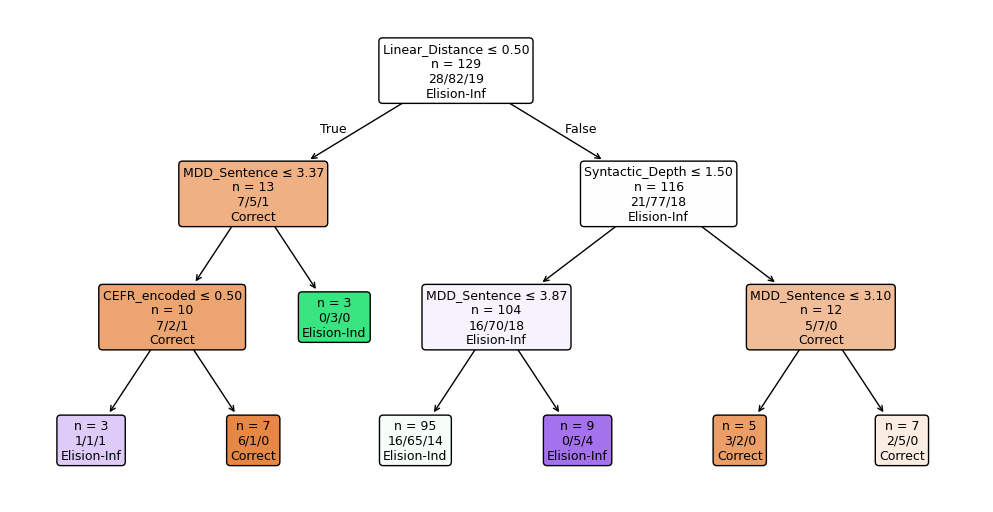

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np, matplotlib.pyplot as plt, re
from sklearn.tree import plot_tree

def plot_tree_clean(tree, X_train, y_train, feature_names, class_names, short_names,
                    path='tree_M1', figsize=(10, 5.2), fontsize=9):
    """Árbol sin solapamientos: regla + n real + recuentos reales por clase + clase predicha."""
    fig, ax = plt.subplots(figsize=figsize)

    annots = plot_tree(tree, feature_names=feature_names, class_names=class_names,
                       filled=True, rounded=True, impurity=False, node_ids=True,
                       label='none', fontsize=fontsize, ax=ax)

    t = tree.tree_
    X_arr = np.asarray(X_train); y_arr = np.asarray(y_train)
    paths = tree.decision_path(X_arr)

    for a in annots:
        text = a.get_text()
        first_line = text.split('\n')[0]

        digits = re.findall(r'\d+', first_line)
        if not digits:
            continue
        node_id = int(digits[0])

        mask = paths[:, node_id].toarray().ravel().astype(bool)
        counts = np.bincount(y_arr[mask], minlength=len(class_names))
        pred = short_names[int(np.argmax(t.value[node_id][0]))]

        lines = []
        if t.children_left[node_id] != -1:
            lines.append(f"{feature_names[t.feature[node_id]]} ≤ {t.threshold[node_id]:.2f}")
        lines += [f"n = {mask.sum()}", "/".join(str(c) for c in counts), pred]
        a.set_text("\n".join(lines))

    plt.tight_layout()
    fig.savefig(f'{path}.png', dpi=300, bbox_inches='tight')
    fig.savefig(f'{path}.svg', bbox_inches='tight')
    plt.show()

plot_tree_clean(
    tree_m1, X1_train, y1_train, FEATURES,
    class_names=M1_CLASSES,
    short_names=['Correct', 'Elision-Ind', 'Elision-Inf'],
)

save(fig, 'figureTree')

In [ ]:
# ════════════════════════════════════════════════════════════════
# STEP F — Numbers
# ════════════════════════════════════════════════════════════════
print("=== Tabla 2: distribución general ===")
print(df['Target_Class'].value_counts())
print((df['Target_Class'].value_counts(normalize=True) * 100).round(2))

print("\n=== Figura 1: % por nivel y clase ===")
print((pd.crosstab(df['CEFR_Level'], df['Target_Class'], normalize='index') * 100).round(1))

print("\n=== 5.2: ISD (Linear_Distance) por clase ===")
print(df.groupby('Target_Class')['Linear_Distance'].describe().round(2))

print("\n=== Tabla 3: aciertos por nivel (M1) ===")
m1 = df_m1.copy()
m1['Is_Correct'] = (m1['Target_Class'] == 'Correct').astype(int)
t3 = m1.groupby('CEFR_Level', observed=True)['Is_Correct'].agg(['sum', 'count', 'mean'])
t3['mean'] = (t3['mean'] * 100).round(1)
print(t3.rename(columns={'sum': 'Correct', 'count': 'N_total', 'mean': '%_Correct'}))

print("\n=== % acierto por nivel y rango de ISD ===")
m1['ISD_range'] = pd.cut(m1['Linear_Distance'], [-1, 0, 2, 999], labels=['0', '1-2', '>=3'])
print((m1.pivot_table(index='CEFR_Level', columns='ISD_range', values='Is_Correct',
                      aggfunc='mean', observed=True) * 100).round(0))

print("\n=== 4.1: textos, palabras y nota media por nivel ===")
tmp = pd.DataFrame(documents)
tmp['words'] = tmp['text'].str.split().str.len()
tmp['lvl'] = tmp['CEFR_level'].map(cefr_mapping)
print(tmp.groupby('lvl')['words'].agg(['count', 'sum', 'min']))
print(tmp.groupby('lvl')['score'].mean().round(1))
print("Total palabras:", tmp['words'].sum())

=== Tabla 2: distribución general ===
Target_Class
Elision_Indicative    109
Correct                38
Elision_Infinitive     25
Hypercorrection        15
Name: count, dtype: int64
Target_Class
Elision_Indicative    58.29
Correct               20.32
Elision_Infinitive    13.37
Hypercorrection        8.02
Name: proportion, dtype: float64

=== Figura 1: % por nivel y clase ===
Target_Class  Correct  Elision_Indicative  Elision_Infinitive  Hypercorrection
CEFR_Level                                                                    
B1               15.4                64.1                15.4              5.1
B2               15.7                68.6                10.0              5.7
C1               26.9                46.2                15.4             11.5

=== 5.2: ISD (Linear_Distance) por clase ===
                    count  mean   std  min   25%  50%  75%   max
Target_Class                                                    
Correct              38.0  1.55  1.54  0.0  0.25  1